# 练习实验：用于手写数字识别的神经网络（二元）

在这个练习中，你将使用一个神经网络来识别手写的数字零和一。


# 大纲
- [ 1 - 包 ](#1)
- [ 2 - 神经网络](#2)
  - [ 2.1 问题描述](#2.1)
  - [ 2.2 数据集](#2.2)
  - [ 2.3 模型表示](#2.3)
  - [ 2.4 Tensorflow 模型实现](#2.4)
    - [ 练习 1](#ex01)
  - [ 2.5 NumPy 模型实现（NumPy 中的前向传播）](#2.5)
    - [ 练习 2](#ex02)
  - [ 2.6 向量化的 NumPy 模型实现（可选）](#2.6)
    - [ 练习 3](#ex03)
  - [ 2.7 恭喜完成！](#2.7)
  - [ 2.8 NumPy 广播教程（可选）](#2.8)

_**注意：** 为避免自动评分器报错，你不允许编辑或删除本 notebook 中的非评分单元格。也请不要添加任何新单元格。
**一旦你通过了本作业**，想要尝试任何非评分代码，可以按照本 notebook 底部的说明操作。_

<a name="1"></a>
## 1 - 包

首先，让我们运行下面的单元格，导入你在本作业中需要用到的所有包。
- [numpy](https://numpy.org/) 是用 Python 进行科学计算的基础包。
- [matplotlib](http://matplotlib.org) 是 Python 中流行的绘图库。
- [tensorflow](https://www.tensorflow.org/) 一个流行的机器学习平台。

In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
import matplotlib.pyplot as plt
from autils import *
%matplotlib inline

import logging
logging.getLogger("tensorflow").setLevel(logging.ERROR)
tf.autograph.set_verbosity(0)

**Tensorflow 与 Keras**  
Tensorflow 是由 Google 开发的一个机器学习包。2019 年，Google 将 Keras 集成到 Tensorflow 中并发布了 Tensorflow 2.0。Keras 是由 François Chollet 独立开发的一个框架，它为 Tensorflow 创建了一个简单的、以层为中心的接口。本课程将使用 Keras 接口。

<a name="2"></a>
## 2 - 神经网络

在课程 1 中，你实现了逻辑回归。它被扩展为使用多项式回归来处理非线性边界。对于更复杂的情形，例如图像识别，神经网络是更好的选择。

<a name="2.1"></a>
### 2.1 问题描述

在这个练习中，你将使用一个神经网络来识别两个手写数字——零和一。这是一个二元分类任务。自动手写数字识别如今被广泛使用——从识别信封上的邮政编码，到识别银行支票上书写的金额。你将在未来的作业中把这个网络扩展到识别全部 10 个数字（0-9）。

本练习将向你展示如何把你学到的方法用于这个分类任务。

<a name="2.2"></a>
### 2.2 数据集

你将从加载本任务的数据集开始。
- 下面显示的 `load_data()` 函数将数据加载到变量 `X` 和 `y` 中


- 该数据集包含 1000 个手写数字的训练样本 $^1$，这里仅限于零和一。

    - 每个训练样本是该数字的一幅 20 像素 x 20 像素的灰度图像。
        - 每个像素由一个浮点数表示，指示该位置的灰度强度。
        - 这个 20 x 20 的像素网格被"展开"成一个 400 维的向量。
        - 每个训练样本成为我们数据矩阵 `X` 中的单独一行。
        - 这给了我们一个 1000 x 400 的矩阵 `X`，其中每一行都是一幅手写数字图像的训练样本。

$$X = 
\left(\begin{array}{cc} 
--- (x^{(1)}) --- \\
--- (x^{(2)}) --- \\
\vdots \\ 
--- (x^{(m)}) --- 
\end{array}\right)$$ 

- 训练集的第二部分是一个 1000 x 1 维的向量 `y`，它包含训练集的标签
    - 如果图像是数字 `0`，则 `y = 0`；如果图像是数字 `1`，则 `y = 1`。

$^1$<sub> 这是 MNIST 手写数字数据集（http://yann.lecun.com/exdb/mnist/）的一个子集</sub>

In [2]:
# load dataset
X, y = load_data()

<a name="toc_89367_2.2.1"></a>
#### 2.2.1 查看变量
让我们进一步熟悉你的数据集。
- 一个好的起点就是打印出每个变量，看看它包含什么。

下面的代码打印变量 `X` 和 `y` 的元素。

In [3]:
print ('The first element of X is: ', X[0])

The first element of X is:  [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+

In [4]:
print ('The first element of y is: ', y[0,0])
print ('The last element of y is: ', y[-1,0])

The first element of y is:  0
The last element of y is:  1


<a name="toc_89367_2.2.2"></a>
#### 2.2.2 检查变量的维度

熟悉数据的另一种方式是查看它的维度。请打印 `X` 和 `y` 的形状，看看你的数据集中有多少个训练样本。

In [5]:
print ('The shape of X is: ' + str(X.shape))
print ('The shape of y is: ' + str(y.shape))

The shape of X is: (1000, 400)
The shape of y is: (1000, 1)


<a name="toc_89367_2.2.3"></a>
#### 2.2.3 可视化数据

你将从可视化训练集的一个子集开始。
- 在下面的单元格中，代码从 `X` 中随机选择 64 行，把每一行映射回一幅 20 像素 x 20 像素的灰度图像，并将这些图像一起显示。
- 每幅图像的标签显示在图像上方

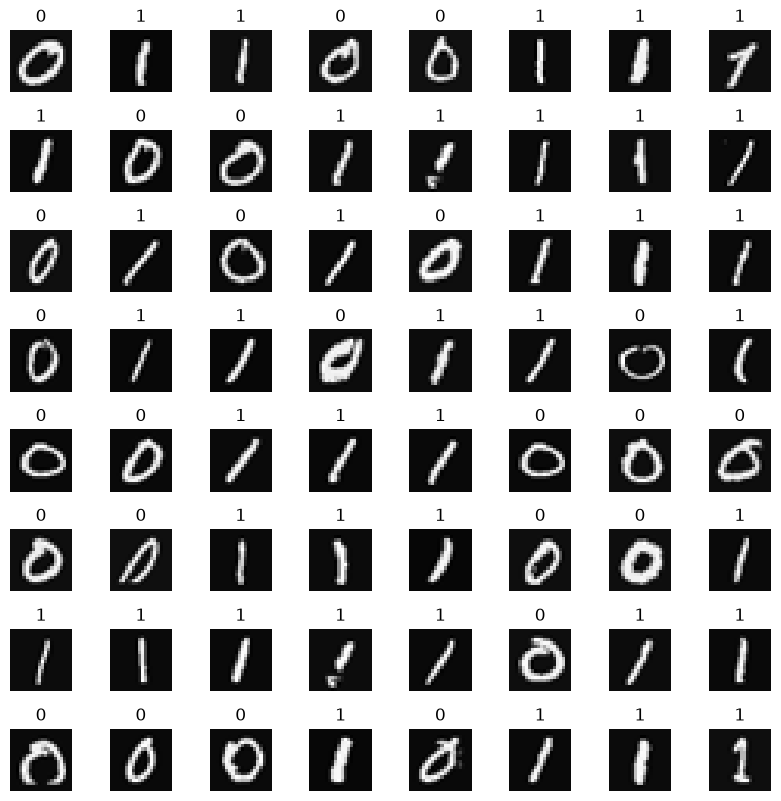

In [6]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
# You do not need to modify anything in this cell

m, n = X.shape

fig, axes = plt.subplots(8,8, figsize=(8,8))
fig.tight_layout(pad=0.1)

for i,ax in enumerate(axes.flat):
    # Select random indices
    random_index = np.random.randint(m)
    
    # Select rows corresponding to the random indices and
    # reshape the image
    X_random_reshaped = X[random_index].reshape((20,20)).T
    
    # Display the image
    ax.imshow(X_random_reshaped, cmap='gray')
    
    # Display the label above the image
    ax.set_title(y[random_index,0])
    ax.set_axis_off()

<a name="2.3"></a>
### 2.3 模型表示

你将在本作业中使用的神经网络如下图所示。
- 它有三个带 sigmoid 激活的稠密层。
    - 回顾一下，我们的输入是数字图像的像素值。
    - 由于图像尺寸为 $20\times20$，这给了我们 $400$ 个输入
    
<img src="images/C2_W1_Assign1.PNG" width="500" height="400">

- 这些参数的维度是按这样一个神经网络来设定的：第 1 层有 $25$ 个单元，第 2 层有 $15$ 个单元，第 3 层有 $1$ 个输出单元。

    - 回顾一下，这些参数的维度确定如下：
        - 如果网络某一层有 $s_{in}$ 个单元，下一层有 $s_{out}$ 个单元，那么
            - $W$ 的维度将是 $s_{in} \times s_{out}$。
            - $b$ 将是一个有 $s_{out}$ 个元素的向量
  
    - 因此，`W` 和 `b` 的形状为
        - layer1：`W1` 的形状是 (400, 25)，`b1` 的形状是 (25,)
        - layer2：`W2` 的形状是 (25, 15)，`b2` 的形状是 (15,)
        - layer3：`W3` 的形状是 (15, 1)，`b3` 的形状是 (1,)
>**注意：** 偏置向量 `b` 可以表示为一维 (n,) 或二维 (1,n) 数组。Tensorflow 使用一维表示，本实验将保持这一约定。

<a name="2.4"></a>
### 2.4 Tensorflow 模型实现

Tensorflow 模型是逐层构建的。一个层的输入维度（上面的 $s_{in}$）会为你计算好。你指定一个层的*输出维度*，这就决定了下一层的输入维度。第一层的输入维度由下面 `model.fit` 语句中指定的输入数据大小推导而来。
>**注意：** 也可以添加一个输入层来指定第一层的输入维度。例如：
`tf.keras.Input(shape=(400,)),    #specify input shape`  
我们这里会包含它，以阐明一些模型尺寸方面的问题。

<a name="ex01"></a>
### 练习 1

在下面，使用 Keras 的 [Sequential 模型](https://keras.io/guides/sequential_model/) 和带 sigmoid 激活的 [Dense 层](https://keras.io/api/layers/core_layers/dense/) 来构建上面描述的网络。

In [7]:
# UNQ_C1
# GRADED CELL: Sequential model

model = Sequential(
    [               
        tf.keras.Input(shape=(400,)),    #specify input size
        ### START CODE HERE ### 
        Dense(units=25,activation='sigmoid'),
        Dense(units=15,activation='sigmoid'),
        Dense(units=1,activation='sigmoid'),
        ### END CODE HERE ### 
    ], name = "my_model" 
)                            


In [8]:
model.summary()

Model: "my_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 25)             │        10,025 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 15)             │           390 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            16 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,431 (40.75 KB)

 Trainable params: 10,431 (40.75 KB)

 Non-trainable params: 0 (0.00 B)

<details>
  <summary><font size="3" color="darkgreen"><b>预期输出（点击展开）</b></font></summary>
`model.summary()` 函数显示了模型的一个有用摘要。因为我们指定了输入层的大小，权重和偏置数组的形状得以确定，因此可以显示每层的参数总数。请注意，各层的名称可能会有所不同，因为它们是自动生成的。
    
    
```
Model: "my_model"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
=================================================================
dense (Dense)                (None, 25)                10025     
_________________________________________________________________
dense_1 (Dense)              (None, 15)                390       
_________________________________________________________________
dense_2 (Dense)              (None, 1)                 16        
=================================================================
Total params: 10,431
Trainable params: 10,431
Non-trainable params: 0
_________________________________________________________________
```

<details>
  <summary><font size="3" color="darkgreen"><b>点击获取提示</b></font></summary>
如讲座中所述：
    
```python
model = Sequential(                      
    [                                   
        tf.keras.Input(shape=(400,)),    # specify input size (optional)
        Dense(25, activation='sigmoid'), 
        Dense(15, activation='sigmoid'), 
        Dense(1,  activation='sigmoid')  
    ], name = "my_model"                                    
)                                       
``` 

In [9]:
# UNIT TESTS
from public_tests import *

test_c1(model)

All tests passed!


摘要中显示的参数数量对应于权重和偏置数组中的元素数量，如下所示。

In [10]:
L1_num_params = 400 * 25 + 25  # W1 parameters  + b1 parameters
L2_num_params = 25 * 15 + 15   # W2 parameters  + b2 parameters
L3_num_params = 15 * 1 + 1     # W3 parameters  + b3 parameters
print("L1 params = ", L1_num_params, ", L2 params = ", L2_num_params, ",  L3 params = ", L3_num_params )

L1 params =  10025 , L2 params =  390 ,  L3 params =  16


我们可以通过先用 `model.layers` 提取各层，然后用 `layerx.get_weights()` 提取权重，来检查模型的细节，如下所示。

In [11]:
[layer1, layer2, layer3] = model.layers

In [12]:
#### Examine Weights shapes
W1,b1 = layer1.get_weights()
W2,b2 = layer2.get_weights()
W3,b3 = layer3.get_weights()
print(f"W1 shape = {W1.shape}, b1 shape = {b1.shape}")
print(f"W2 shape = {W2.shape}, b2 shape = {b2.shape}")
print(f"W3 shape = {W3.shape}, b3 shape = {b3.shape}")

W1 shape = (400, 25), b1 shape = (25,)
W2 shape = (25, 15), b2 shape = (15,)
W3 shape = (15, 1), b3 shape = (1,)


**预期输出**
```
W1 shape = (400, 25), b1 shape = (25,)  
W2 shape = (25, 15), b2 shape = (15,)  
W3 shape = (15, 1), b3 shape = (1,)
```

`xx.get_weights` 返回一个 NumPy 数组。也可以直接以张量形式访问权重。请注意最后一层中张量的形状。

In [13]:
print(model.layers[2].weights)

[<Variable path=my_model/dense_2/kernel, shape=(15, 1), dtype=float32, value=[[ 0.28977835]
 [-0.42155063]
 [ 0.48350912]
 [ 0.25629026]
 [-0.15282753]
 [-0.1955559 ]
 [-0.500807  ]
 [-0.45207626]
 [ 0.47050256]
 [-0.29516622]
 [ 0.4695794 ]
 [ 0.5575703 ]
 [ 0.16729301]
 [-0.39187813]
 [ 0.5317392 ]]>, <Variable path=my_model/dense_2/bias, shape=(1,), dtype=float32, value=[0.]>]


下面的代码将定义一个损失函数并运行梯度下降，将模型的权重拟合到训练数据。这将在接下来的一周更详细地解释。

In [14]:
model.compile(
    loss=tf.keras.losses.BinaryCrossentropy(),
    optimizer=tf.keras.optimizers.Adam(0.001),
)

model.fit(
    X,y,
    epochs=20
)

Epoch 1/20


32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.5984   
Epoch 2/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.5984   
Epoch 2/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 1000us/step - loss: 0.4163
Epoch 3/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 1000us/step - loss: 0.4163
Epoch 3/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.2684 
Epoch 4/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.2684 
Epoch 4/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.1790 
Epoch 5/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.1790 
Epoch 5/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 952us/step - loss: 0.1285
Epoch 6/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 952us/step - loss: 0.1285
Epoch 6/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 877us/step - loss: 0.0982
Epoch 7/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 877us/step - loss: 0.0982
Epoch 7/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0785 
Epoch 8/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0785 
Epoch 8/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0650 
Epoch 9/2

要在一个样本上运行模型以做出预测，请使用 [Keras `predict`](https://www.tensorflow.org/api_docs/python/tf/keras/Model)。`predict` 的输入是一个数组，所以单个样本被 reshape 成二维的。

In [15]:
prediction = model.predict(X[0].reshape(1,400))  # a zero
print(f" predicting a zero: {prediction}")
prediction = model.predict(X[500].reshape(1,400))  # a one
print(f" predicting a one:  {prediction}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
 predicting a zero: [[0.01634966]]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
 predicting a zero: [[0.01634966]]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
 predicting a one:  [[0.98881197]]
 predicting a one:  [[0.98881197]]


模型的输出被解释为一个概率。在上面的第一个例子中，输入是一个零。模型预测输入是一的概率接近于零。
在第二个例子中，输入是一个一。模型预测输入是一的概率接近于一。
与逻辑回归的情形一样，将该概率与一个阈值进行比较，以做出最终预测。

In [16]:
if prediction >= 0.5:
    yhat = 1
else:
    yhat = 0
print(f"prediction after threshold: {yhat}")

prediction after threshold: 1


让我们对随机抽取的 64 个数字比较预测值与标签。这需要一点时间运行。

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━

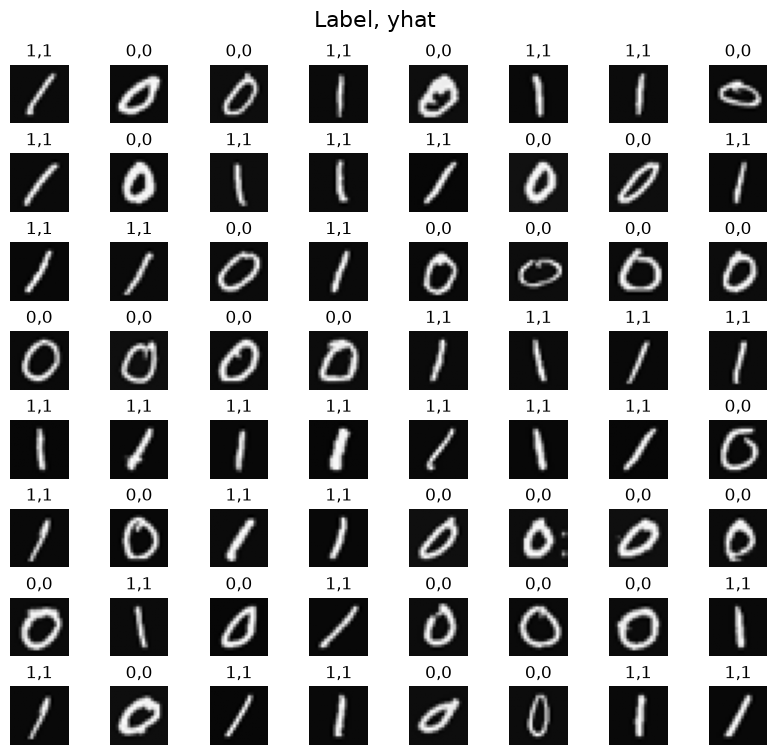

In [17]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
# You do not need to modify anything in this cell

m, n = X.shape

fig, axes = plt.subplots(8,8, figsize=(8,8))
fig.tight_layout(pad=0.1,rect=[0, 0.03, 1, 0.92]) #[left, bottom, right, top]

for i,ax in enumerate(axes.flat):
    # Select random indices
    random_index = np.random.randint(m)
    
    # Select rows corresponding to the random indices and
    # reshape the image
    X_random_reshaped = X[random_index].reshape((20,20)).T
    
    # Display the image
    ax.imshow(X_random_reshaped, cmap='gray')
    
    # Predict using the Neural Network
    prediction = model.predict(X[random_index].reshape(1,400))
    if prediction >= 0.5:
        yhat = 1
    else:
        yhat = 0
    
    # Display the label above the image
    ax.set_title(f"{y[random_index,0]},{yhat}")
    ax.set_axis_off()
fig.suptitle("Label, yhat", fontsize=16)
plt.show()

<a name="2.5"></a>
### 2.5 NumPy 模型实现（NumPy 中的前向传播）
如讲座中所述，可以使用 NumPy 构建你自己的稠密层。然后可以用它来构建一个多层神经网络。

<img src="images/C2_W1_dense2.PNG" width="600" height="450">

<a name="ex02"></a>
### 练习 2

在下面，构建一个稠密层子程序。讲座中的例子使用一个 for 循环来访问层中的每个单元（`j`），对该单元的权重（`W[:,j]`）执行点积，并加上该单元的偏置（`b[j]`）以形成 `z`。然后对该结果应用一个激活函数 `g(z)`。本节不会使用可选讲座中描述的一些矩阵运算。这些将在后面一节中探讨。

In [18]:
# UNQ_C2
# GRADED FUNCTION: my_dense

def my_dense(a_in, W, b, g):
    """
    Computes dense layer
    Args:
      a_in (ndarray (n, )) : Data, 1 example 
      W    (ndarray (n,j)) : Weight matrix, n features per unit, j units
      b    (ndarray (j, )) : bias vector, j units  
      g    activation function (e.g. sigmoid, relu..)
    Returns
      a_out (ndarray (j,))  : j units
    """
    units = W.shape[1]
    a_out = np.zeros(units)
### START CODE HERE ### 
    for j in range(units):
        a_out[j]=g(np.dot(a_in,W[:,j])+b[j])
        
        
        
### END CODE HERE ### 
    return(a_out)


In [19]:
# Quick Check
x_tst = 0.1*np.arange(1,3,1).reshape(2,)  # (1 examples, 2 features)
W_tst = 0.1*np.arange(1,7,1).reshape(2,3) # (2 input features, 3 output features)
b_tst = 0.1*np.arange(1,4,1).reshape(3,)  # (3 features)
A_tst = my_dense(x_tst, W_tst, b_tst, sigmoid)
print(A_tst)

[0.54735762 0.57932425 0.61063923]


**预期输出**
```
[0.54735762 0.57932425 0.61063923]
```

<details>
  <summary><font size="3" color="darkgreen"><b>点击获取提示</b></font></summary>
如讲座中所述：
    
```python
def my_dense(a_in, W, b, g):
    """
    Computes dense layer
    Args:
      a_in (ndarray (n, )) : Data, 1 example 
      W    (ndarray (n,j)) : Weight matrix, n features per unit, j units
      b    (ndarray (j, )) : bias vector, j units  
      g    activation function (e.g. sigmoid, relu..)
    Returns
      a_out (ndarray (j,))  : j units
    """
    units = W.shape[1]
    a_out = np.zeros(units)
    for j in range(units):             
        w =                            # Select weights for unit j. These are in column j of W
        z =                            # dot product of w and a_in + b
        a_out[j] =                     # apply activation to z
    return(a_out)
```
   
    
<details>
  <summary><font size="3" color="darkgreen"><b>点击获取更多提示</b></font></summary>

    
```python
def my_dense(a_in, W, b, g):
    """
    Computes dense layer
    Args:
      a_in (ndarray (n, )) : Data, 1 example 
      W    (ndarray (n,j)) : Weight matrix, n features per unit, j units
      b    (ndarray (j, )) : bias vector, j units  
      g    activation function (e.g. sigmoid, relu..)
    Returns
      a_out (ndarray (j,))  : j units
    """
    units = W.shape[1]
    a_out = np.zeros(units)
    for j in range(units):             
        w = W[:,j]                     
        z = np.dot(w, a_in) + b[j]     
        a_out[j] = g(z)                
    return(a_out)
``` 

In [20]:
# UNIT TESTS

test_c2(my_dense)

All tests passed!


下面的单元格利用上面的 `my_dense` 子程序构建了一个三层神经网络。

In [21]:
def my_sequential(x, W1, b1, W2, b2, W3, b3):
    a1 = my_dense(x,  W1, b1, sigmoid)
    a2 = my_dense(a1, W2, b2, sigmoid)
    a3 = my_dense(a2, W3, b3, sigmoid)
    return(a3)

我们可以从 Tensorflow 复制训练好的权重和偏置。

In [22]:
W1_tmp,b1_tmp = layer1.get_weights()
W2_tmp,b2_tmp = layer2.get_weights()
W3_tmp,b3_tmp = layer3.get_weights()

In [23]:
# make predictions
prediction = my_sequential(X[0], W1_tmp, b1_tmp, W2_tmp, b2_tmp, W3_tmp, b3_tmp )
if prediction >= 0.5:
    yhat = 1
else:
    yhat = 0
print( "yhat = ", yhat, " label= ", y[0,0])
prediction = my_sequential(X[500], W1_tmp, b1_tmp, W2_tmp, b2_tmp, W3_tmp, b3_tmp )
if prediction >= 0.5:
    yhat = 1
else:
    yhat = 0
print( "yhat = ", yhat, " label= ", y[500,0])

yhat =  0  label=  0
yhat =  1  label=  1


运行下面的单元格，看看来自 Numpy 模型和 Tensorflow 模型的预测。这需要一点时间运行。

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━

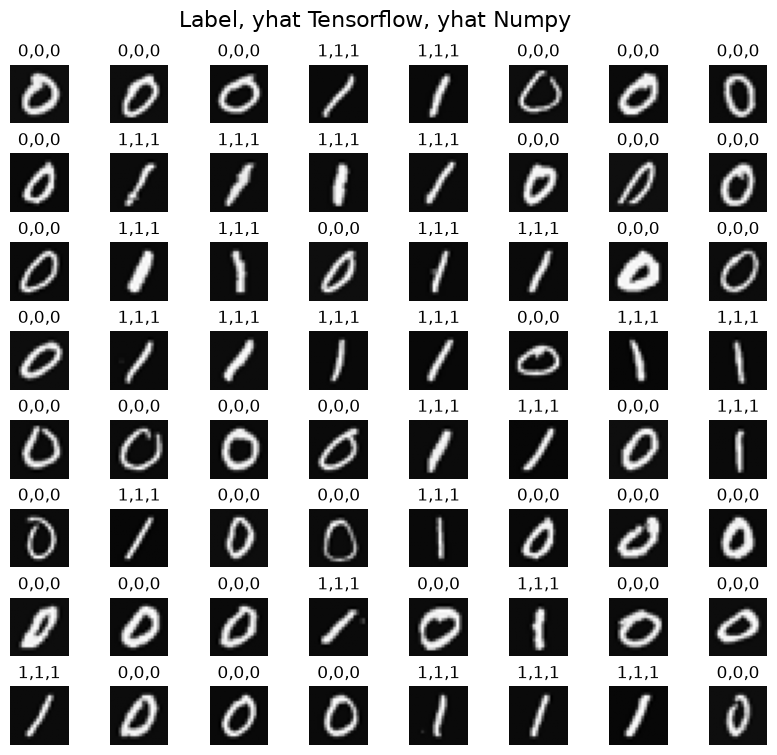

In [24]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
# You do not need to modify anything in this cell

m, n = X.shape

fig, axes = plt.subplots(8,8, figsize=(8,8))
fig.tight_layout(pad=0.1,rect=[0, 0.03, 1, 0.92]) #[left, bottom, right, top]

for i,ax in enumerate(axes.flat):
    # Select random indices
    random_index = np.random.randint(m)
    
    # Select rows corresponding to the random indices and
    # reshape the image
    X_random_reshaped = X[random_index].reshape((20,20)).T
    
    # Display the image
    ax.imshow(X_random_reshaped, cmap='gray')

    # Predict using the Neural Network implemented in Numpy
    my_prediction = my_sequential(X[random_index], W1_tmp, b1_tmp, W2_tmp, b2_tmp, W3_tmp, b3_tmp )
    my_yhat = int(np.squeeze(my_prediction) >= 0.5)

    # Predict using the Neural Network implemented in Tensorflow
    tf_prediction = model.predict(X[random_index].reshape(1,400))
    tf_yhat = int(np.squeeze(tf_prediction) >= 0.5)
    
    # Display the label above the image
    ax.set_title(f"{y[random_index,0]},{tf_yhat},{my_yhat}")
    ax.set_axis_off() 
fig.suptitle("Label, yhat Tensorflow, yhat Numpy", fontsize=16)
plt.show()

<a name="2.6"></a>
### 2.6 向量化的 NumPy 模型实现（可选）
可选讲座描述了可用于加速计算的向量和矩阵运算。
下面描述了一种层运算，它为给定的输入样本计算一个层中所有单元的输出：

<img src="images/C2_W1_VectorMatrix.PNG" width="600" height="450">

我们可以用上面的样本 `X` 以及 `W1`、`b1` 参数来演示这一点。我们使用 `np.matmul` 来执行矩阵乘法。请注意，x 和 W 的维度必须兼容，如上图所示。

In [25]:
x = X[0].reshape(-1,1)         # column vector (400,1)
z1 = np.matmul(x.T,W1) + b1    # (1,400)(400,25) = (1,25)
a1 = sigmoid(z1)
print(a1.shape)

(1, 25)


你可以更进一步，在一次矩阵-矩阵运算中为所有样本计算所有单元。

<img src="images/C2_W1_MatrixMatrix.PNG" width="600" height="450">
完整的运算是 $\mathbf{Z}=\mathbf{XW}+\mathbf{b}$。这将利用 NumPy 广播把 $\mathbf{b}$ 扩展成 $m$ 行。如果你对此不熟悉，notebook 末尾提供了一个简短的教程。

<a name="ex03"></a>
### 练习 3

在下面，编写一个新的 `my_dense_v` 子程序，它对一个样本矩阵执行层的计算。这将用到 `np.matmul()`。

_**注意**：这个函数不计入评分，因为它在关于向量化的可选讲座中讨论过。如果你没有看过它们，可以随意点击预期代码下方的提示来查看代码。即使这里留空，你也可以提交 notebook。_

In [26]:
# UNQ_C3
# UNGRADED FUNCTION: my_dense_v

def my_dense_v(A_in, W, b, g):
    """
    Computes dense layer
    Args:
      A_in (ndarray (m,n)) : Data, m examples, n features each
      W    (ndarray (n,j)) : Weight matrix, n features per unit, j units
      b    (ndarray (1,j)) : bias vector, j units  
      g    activation function (e.g. sigmoid, relu..)
    Returns
      A_out (tf.Tensor or ndarray (m,j)) : m examples, j units
    """
### START CODE HERE ### 
    A_out=g(np.matmul(A_in,W)+b)
    
### END CODE HERE ### 
    return(A_out)

In [27]:
X_tst = 0.1*np.arange(1,9,1).reshape(4,2) # (4 examples, 2 features)
W_tst = 0.1*np.arange(1,7,1).reshape(2,3) # (2 input features, 3 output features)
b_tst = 0.1*np.arange(1,4,1).reshape(1,3) # (1,3 features)
A_tst = my_dense_v(X_tst, W_tst, b_tst, sigmoid)
print(A_tst)

[[0.54735762 0.57932425 0.61063923]
 [0.57199613 0.61301418 0.65248946]
 [0.5962827  0.64565631 0.6921095 ]
 [0.62010643 0.67699586 0.72908792]]


**预期输出**

```
[[0.54735762 0.57932425 0.61063923]
 [0.57199613 0.61301418 0.65248946]
 [0.5962827  0.64565631 0.6921095 ]
 [0.62010643 0.67699586 0.72908792]]
 ```

<details>
  <summary><font size="3" color="darkgreen"><b>点击获取提示</b></font></summary>
    用矩阵形式，这可以用一两行写出来。
    
       Z = np.matmul of A_in and W plus b    
       A_out is g(Z)  
<details>
  <summary><font size="3" color="darkgreen"><b>点击获取代码</b></font></summary>

```python
def my_dense_v(A_in, W, b, g):
    """
    Computes dense layer
    Args:
      A_in (ndarray (m,n)) : Data, m examples, n features each
      W    (ndarray (n,j)) : Weight matrix, n features per unit, j units
      b    (ndarray (j,1)) : bias vector, j units  
      g    activation function (e.g. sigmoid, relu..)
    Returns
      A_out (ndarray (m,j)) : m examples, j units
    """
    Z = np.matmul(A_in,W) + b    
    A_out = g(Z)                 
    return(A_out)
```

In [28]:
# UNIT TESTS

test_c3(my_dense_v)

All tests passed!


下面的单元格利用上面的 `my_dense_v` 子程序构建了一个三层神经网络。

In [29]:
def my_sequential_v(X, W1, b1, W2, b2, W3, b3):
    A1 = my_dense_v(X,  W1, b1, sigmoid)
    A2 = my_dense_v(A1, W2, b2, sigmoid)
    A3 = my_dense_v(A2, W3, b3, sigmoid)
    return(A3)

我们可以再次从 Tensorflow 复制训练好的权重和偏置。

In [30]:
W1_tmp,b1_tmp = layer1.get_weights()
W2_tmp,b2_tmp = layer2.get_weights()
W3_tmp,b3_tmp = layer3.get_weights()

让我们用新模型做一个预测。这将*一次性对所有样本*做出预测。请注意输出的形状。

In [31]:
Prediction = my_sequential_v(X, W1_tmp, b1_tmp, W2_tmp, b2_tmp, W3_tmp, b3_tmp )
Prediction.shape

(1000, 1)

我们将像之前一样应用 0.5 的阈值，但一次性应用于所有预测。

In [32]:
Yhat = (Prediction >= 0.5).astype(int)
print("predict a zero: ",Yhat[0], "predict a one: ", Yhat[500])

predict a zero:  [0] predict a one:  [1]


运行下面的单元格查看预测。这将使用我们上面刚计算出的预测。这需要一点时间运行。

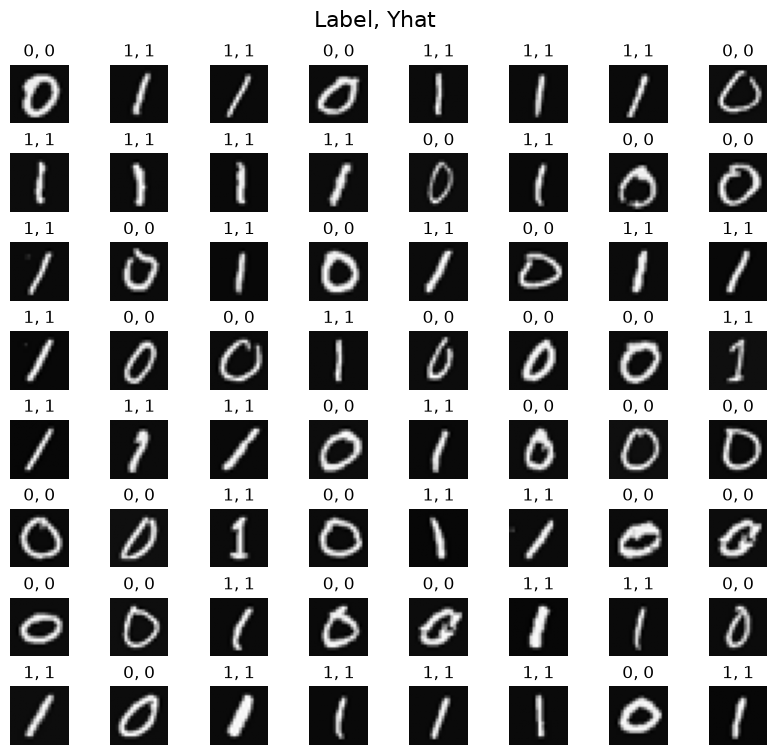

In [33]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
# You do not need to modify anything in this cell

m, n = X.shape

fig, axes = plt.subplots(8, 8, figsize=(8, 8))
fig.tight_layout(pad=0.1, rect=[0, 0.03, 1, 0.92]) #[left, bottom, right, top]

for i, ax in enumerate(axes.flat):
    # Select random indices
    random_index = np.random.randint(m)
    
    # Select rows corresponding to the random indices and
    # reshape the image
    X_random_reshaped = X[random_index].reshape((20, 20)).T
    
    # Display the image
    ax.imshow(X_random_reshaped, cmap='gray')
   
    # Display the label above the image
    ax.set_title(f"{y[random_index,0]}, {Yhat[random_index, 0]}")
    ax.set_axis_off() 
fig.suptitle("Label, Yhat", fontsize=16)
plt.show()

你可以看看其中一个被错误分类的图像是什么样子。

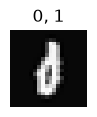

In [34]:
fig = plt.figure(figsize=(1, 1))
errors = np.where(y != Yhat)
random_index = errors[0][0]
X_random_reshaped = X[random_index].reshape((20, 20)).T
plt.imshow(X_random_reshaped, cmap='gray')
plt.title(f"{y[random_index,0]}, {Yhat[random_index, 0]}")
plt.axis('off')
plt.show()

<a name="2.7"></a>
### 2.7 恭喜完成！
你已经成功构建并使用了一个神经网络。

<a name="2.8"></a>
### 2.8 NumPy 广播教程（可选）

在最后一个例子中，$\mathbf{Z}=\mathbf{XW} + \mathbf{b}$ 利用了 NumPy 广播来扩展向量 $\mathbf{b}$。如果你不熟悉 NumPy 广播，这里提供了一个简短的教程。

$\mathbf{XW}$ 是一个矩阵-矩阵运算，维度为 $(m,j_1)(j_1,j_2)$，结果是一个维度为 $(m,j_2)$ 的矩阵。在此之上，我们加上一个维度为 $(1,j_2)$ 的向量 $\mathbf{b}$。要使这个逐元素运算有意义，$\mathbf{b}$ 必须被扩展成一个 $(m,j_2)$ 矩阵。这个扩展由 NumPy 广播为你完成。

广播适用于逐元素运算。
它的基本操作是通过复制元素来"拉伸"一个较小的维度，以匹配一个较大的维度。

更[具体地](https://NumPy.org/doc/stable/user/basics.broadcasting.html)：
在对两个数组进行运算时，NumPy 会逐元素地比较它们的形状。它从末尾（即最右边）的维度开始，向左进行。当满足以下条件时，两个维度是兼容的
- 它们相等，或
- 其中一个是 1   

如果不满足这些条件，就会抛出一个 ValueError: operands could not be broadcast together 异常，表明这些数组具有不兼容的形状。结果数组的大小是输入沿每个轴上不为 1 的那个大小。

下面是一些例子：

<figure>
    <center> <img src="./images/C2_W1_Assign1_BroadcastIndexes.PNG"  alt='missing' width="400"  ><center/>
    <figcaption>计算广播结果的形状</figcaption>
<figure/>

下面的图描述了维度的扩展。请注意下面的红色文字：

<figure>
    <center> <img src="./images/C2_W1_Assign1_Broadcasting.gif"  alt='missing' width="600"  ><center/>
    <figcaption>广播在概念上扩展参数，以匹配进行逐元素运算</figcaption>
<figure/>

上图展示了 NumPy 在最终运算之前扩展参数以进行匹配。请注意这是一种概念性的描述。NumPy 运算的实际机制会选择最高效的实现。

对于下面的每个例子，试着在运行之前猜出结果的大小。

In [35]:
a = np.array([1,2,3]).reshape(-1,1)  #(3,1)
b = 5
print(f"(a + b).shape: {(a + b).shape}, \na + b = \n{a + b}")

(a + b).shape: (3, 1), 
a + b = 
[[6]
 [7]
 [8]]


请注意，这适用于所有逐元素运算：

In [36]:
a = np.array([1,2,3]).reshape(-1,1)  #(3,1)
b = 5
print(f"(a * b).shape: {(a * b).shape}, \na * b = \n{a * b}")

(a * b).shape: (3, 1), 
a * b = 
[[ 5]
 [10]
 [15]]


<figure>
    <img src="./images/C2_W1_Assign1_VectorAdd.PNG"  alt='missing' width="740" >
    <center><figcaption><b>行-列逐元素运算</b></figcaption></center>
<figure/>

In [37]:
a = np.array([1,2,3,4]).reshape(-1,1)
b = np.array([1,2,3]).reshape(1,-1)
print(a)
print(b)
print(f"(a + b).shape: {(a + b).shape}, \na + b = \n{a + b}")

[[1]
 [2]
 [3]
 [4]]
[[1 2 3]]
(a + b).shape: (4, 3), 
a + b = 
[[2 3 4]
 [3 4 5]
 [4 5 6]
 [5 6 7]]


这就是你在上面构建的稠密层中的情形。把一个一维向量 $b$ 加到一个 (m,j) 矩阵上。
<figure>
    <img src="./images/C2_W1_Assign1_BroadcastMatrix.PNG"  alt='missing' width="740" >
    <center><figcaption><b>矩阵 + 一维向量</b></figcaption></center>
<figure/>

<details>
  <summary><font size="2" color="darkgreen"><b>如果你想尝试任何非评分代码，请点击这里。</b></font></summary>
    <p><i><b>重要提示：请只在你已经通过本作业后再这样做，以避免自动评分器出现问题。</b></i>
    <ol>
        <li> 在 notebook 的菜单上，点击 “View” > “Cell Toolbar” > “Edit Metadata”</li>
        <li> 点击你想锁定/解锁的代码单元格旁边的 “Edit Metadata” 按钮</li>
        <li> 将 “editable” 的属性值设置为：
            <ul>
                <li> “true” 如果你想解锁它 </li>
                <li> “false” 如果你想锁定它 </li>
            </ul>
        </li>
        <li> 在 notebook 的菜单上，点击 “View” > “Cell Toolbar” > “None” </li>
    </ol>
    <p> 下面是如何执行上述步骤的简短演示：
        <br>
        <img src="https://drive.google.com/uc?export=view&id=14Xy_Mb17CZVgzVAgq7NCjMVBvSae3xO1" align="center" alt="unlock_cells.gif">
</details>